# Practical 2: Describing Data
## 6COM2005 Data Mining and Visualisation

In this practical you will:
- Calculate the centre of a feature (mean, median, mode) by hand in Python and with pandas.
- Calculate the spread (range, IQR, variance, standard deviation) and understand n vs n − 1.
- Describe the shape of a distribution with histograms and box plots, and find outliers.
- Scale features with the z-score and min–max normalisation, and see why it matters for distances.

## Part 1: Load and Prepare

In [8]:
# 1.1 Import pandas, numpy, and matplotlib.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# 1.2 Load `penguins.csv`, remove rows with missing values, and save the result as `df`. Print the number of rows.
df = pd.read_csv("penguins.csv").dropna()
print(len(df))

333


In [12]:
# 1.3 Save the body mass column as a list called `mass`.
mass = list(df["body_mass_g"])

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 1: loaded data"
git push
</pre>

## Part 2: Centre

In [13]:
# 2.1 Calculate the mean of `mass` with `sum()` and `len()`. Check it with pandas `.mean()`.
mean = sum(mass) / len(mass)
print(mean, df["body_mass_g"].mean())

4207.057057057057 4207.057057057057


In [14]:
# 2.2 Calculate the median yourself: sort the list and take the middle value (or the mean of the two middle values). Check it with `.median()`.
s = sorted(mass)
n = len(s)
if n % 2 == 1:
    median = s[n // 2]
else:
    median = (s[n // 2 - 1] + s [n // 2]) / 2
print(median, df["body_mass_g"].median())

4050.0 4050.0


In [15]:
# 2.3 Find the mode of the species column.
df["species"].mode()

0    Adelie
Name: species, dtype: object

In [16]:
# 2.4 Add one wrong value, 60000 g, to a copy of `mass`. Calculate the new mean and median.
wrong = mass + [60000]
print(np.mean(wrong), np.median(wrong))

4374.101796407185 4050.0


**2.5 In a markdown cell: which measure changed more in 2.4? Why?**

the mean changed because the wrong value is higher then the other values

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 2: centre"
git push
</pre>

## Part 3: Spread

In [18]:
# 3.1 Calculate the range and the IQR of body mass. Use `.quantile(0.25)` and `.quantile(0.75)
col = df["body_mass_g"]
print("range:", col.max() - col.min())
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
print("Q1:", q1, "Q3:", q3, "IQR:", q3 - q1)

range: 3600.0
Q1: 3550.0 Q3: 4775.0 IQR: 1225.0


In [19]:
# 3.2 Calculate the population variance and SD of body mass yourself with the five steps from the lecture.
squares = [(x - mean) ** 2 for x in mass]
var_pop = sum(squares) / len(mass)
sd_pop = var_pop**0.5
print(var_pop, sd_pop)

646425.423170919 804.0058601595631


In [20]:
# 3.3 Calculate the sample SD yourself (divide by n − 1). Compare with `np.std()` and pandas `.std()`.
sd_sample = (sum(squares) / (len(mass) - 1)) ** 0.5
print(sd_sample)
print("numpy:", np.std(mass))
print("pandas:", df["body_mass_g"].std())

805.2158019428966
numpy: 804.0058601595629
pandas: 805.2158019428966


**3.4 In a markdown cell: which function divides by n and which by n − 1? Why is the difference so small here?**

NumPy's std() divides by n, while pandas' std() divides by n - 1. The difference is small because the dataset has a lot of values, so n and n - 1 are almost the same.

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 3: spread"
git push
</pre>

## Part 4: Shape and Outliers

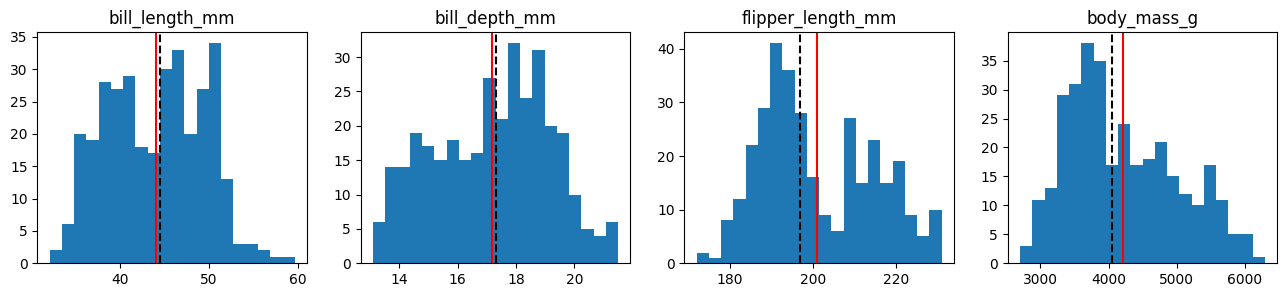

In [23]:
# 4.1 Draw a histogram of each of the four numeric measurements, with a red line at the mean and a black dashed line at the median.
cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3))

for ax, c in zip(axes, cols):
    ax.hist(df[c], bins=20)
    ax.axvline(df[c].mean(), color="red")
    ax.axvline(df[c].median(), color="black", linestyle="--")
    ax.set_title(c)

plt.show()

**4.2 In a markdown cell: describe the shape of each histogram (symmetric, skewed, bimodal).**
Bill length is slightly skewed, while bill depth looks roughly symmetric. Flipper length and body mass appear bimodal, with two main peaks in their distributions.


In [22]:
# 4.3 Write a function `iqr_outliers(col)` that returns the values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. Use it on each numeric column.
def iqr_outliers(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return col[(col < lower) | (col > upper)]

for c in cols:
    print(c, iqr_outliers(df[c]).values)

bill_length_mm []
bill_depth_mm []
flipper_length_mm []
body_mass_g []


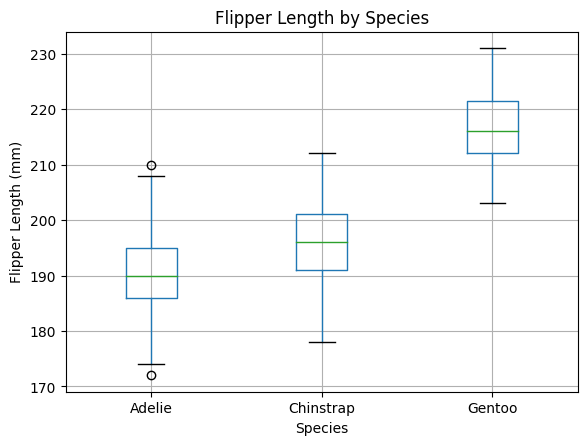

In [24]:
# 4.4 Draw box plots of flipper length for each species.
df.boxplot(column="flipper_length_mm", by="species")
plt.title("Flipper Length by Species")
plt.suptitle("")
plt.xlabel("Species")
plt.ylabel("Flipper Length (mm)")
plt.show()

<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 4: shape and outliers"
git push
</pre>

## Part 5: Scaling

In [25]:
# 5.1 Standardise flipper length with the z-score formula. Check that the new mean is 0 and the SD is 1.
f = df["flipper_length_mm"]
z = (f - f.mean()) / f.std()
print(round(z.mean(), 6), round(z.std(), 6))

0.0 1.0


In [26]:
# 5.2 Normalise body mass with min–max normalisation. Print the new min and max.
b = df["body_mass_g"]
mm = (b - b.min()) / (b.max() - b.min())
print(mm.min(), mm.max())

0.0 1.0


In [27]:
# 5.3 Take the first two penguins. Calculate their Euclidean distance using bill depth (mm) and body mass (g), first on the raw values and then on the z-scores.
pair = ["bill_depth_mm", "body_mass_g"]
two = df[pair].iloc[:2]
print(two)

raw = np.sqrt(((two.iloc[0] - two.iloc[1]) ** 2).sum())
z = (df[pair] - df[pair].mean()) / df[pair].std()
scaled = np.sqrt(((z.iloc[0] - z.iloc[1]) ** 2).sum())

print("raw:", raw, "scaled:", scaled)

   bill_depth_mm  body_mass_g
0           18.7       3750.0
1           17.4       3800.0
raw: 50.016897144864956 scaled: 0.6630686276800881


**5.4 In a markdown cell: which feature decides the raw distance? Why must we scale before K-Means or KNN?**
Body mass has the biggest effect on the raw distance because its values are much larger than bill depth. We need to scale the data before using K-Means or KNN so that all features are treated fairly and one feature doesn't dominate the distance calculation.


<pre>
Commit and push your work:

git status
git add .
git commit -m "Part 5: scaling"
git push
</pre>